# 10. Байесовская реконструкция события в PyMC

Сначала генерируется отклик каждого ФЭУ для одиночного события с известными энергией и положением. Затем этот отклик передаётся в PyMC как `observed`, а энергия и координаты источника восстанавливаются по их апостериорному распределению.

В модели используется приближение малых фотокатодов: вероятность попадания в ФЭУ оценивается по его эффективной площади, расстоянию и углу падения. Условное распределение числа фотоэлектронов моделируется отрицательным биномиальным распределением, согласованным по среднему и дисперсии с пуассоновским числом попаданий и пуассоновским откликом одного попадания.

In [1]:
%pip install -q pymc arviz numpy matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


WARNING (pytensor.configdefaults): g++ not available, if using conda: `conda install gxx`
WARNING (pytensor.configdefaults): g++ not detected!  PyTensor will be unable to compile C-implementations and will default to Python. Performance may be severely degraded. To remove this warning, set PyTensor flags cxx to an empty string.


Истинная энергия: 1.00 МэВ
Истинное положение, см: [ 30. -20.  40.]
Испущено фотонов: 10000
Попаданий в ФЭУ: 237
Заряд по ФЭУ (фотоэлектроны): [3, 8, 4, 8, 1, 4, 1, 1, 8, 4, 3, 7, 4, 3, 4, 2, 1, 3, 0, 2, 8, 4, 5, 3, 3, 0, 3, 1, 1, 3, 7, 1, 0, 2, 2, 3, 4, 3, 3, 2]
Полный заряд: 129 фотоэлектронов


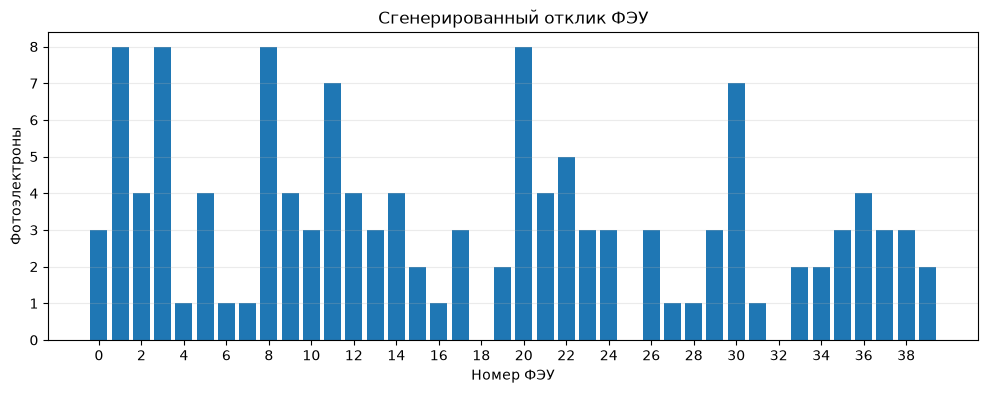

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pymc as pm
import arviz as az

DETECTOR_RADIUS_CM = 200.0
NUMBER_OF_PMTS = 40
PMT_RADIUS_CM = 10.0
LIGHT_YIELD = 10_000  # photons / MeV
PHOTOELECTRONS_PER_HIT = 0.5
TRUE_ENERGY_MEV = 1.0
TRUE_POSITION_CM = np.array([30.0, -20.0, 40.0])
NUMBER_OF_PHOTONS = round(LIGHT_YIELD * TRUE_ENERGY_MEV)
RANDOM_SEED = 20261101

indices = np.arange(NUMBER_OF_PMTS)
polar = np.arccos(1.0 - 2.0 * (indices + 0.5) / NUMBER_OF_PMTS)
azimuth = np.pi * (1.0 + np.sqrt(5.0)) * indices
pmt_normals = np.column_stack((
    np.cos(azimuth) * np.sin(polar),
    np.sin(azimuth) * np.sin(polar),
    np.cos(polar),
))
pmt_positions = DETECTOR_RADIUS_CM * pmt_normals

def generate_pmt_sample(energy_mev, source_position_cm, rng):
    """Трассировка фотонов и отклик ФЭУ по геометрии задач 1–3."""
    source_position_cm = np.asarray(source_position_cm, dtype=float)
    if source_position_cm.shape != (3,):
        raise ValueError("Положение источника должно содержать три координаты")
    if energy_mev < 0:
        raise ValueError("Энергия должна быть неотрицательной")
    if np.dot(source_position_cm, source_position_cm) >= DETECTOR_RADIUS_CM**2:
        raise ValueError("Источник должен находиться внутри детектора")

    photon_count = round(LIGHT_YIELD * energy_mev)
    cos_theta = rng.uniform(-1.0, 1.0, photon_count)
    phi = rng.uniform(0.0, 2.0 * np.pi, photon_count)
    sin_theta = np.sqrt(1.0 - cos_theta**2)
    directions = np.column_stack((
        sin_theta * np.cos(phi),
        sin_theta * np.sin(phi),
        cos_theta,
    ))

    source_dot_direction = directions @ source_position_cm
    distance_to_boundary = -source_dot_direction + np.sqrt(
        source_dot_direction**2
        + DETECTOR_RADIUS_CM**2
        - np.dot(source_position_cm, source_position_cm)
    )
    boundary_points = source_position_cm + distance_to_boundary[:, None] * directions
    projections = boundary_points @ pmt_normals.T
    projection_threshold = np.sqrt(DETECTOR_RADIUS_CM**2 - PMT_RADIUS_CM**2)
    pmt_indices = np.argmax(projections, axis=1)
    hit_mask = projections[np.arange(photon_count), pmt_indices] >= projection_threshold
    hits_per_pmt = np.bincount(pmt_indices[hit_mask], minlength=NUMBER_OF_PMTS)

    photoelectrons = rng.poisson(PHOTOELECTRONS_PER_HIT * hits_per_pmt)
    return hits_per_pmt, photoelectrons


rng = np.random.default_rng(RANDOM_SEED)
hits_per_pmt, photoelectrons_observed = generate_pmt_sample(
    TRUE_ENERGY_MEV,
    TRUE_POSITION_CM,
    rng,
)

print(f"Истинная энергия: {TRUE_ENERGY_MEV:.2f} МэВ")
print(f"Истинное положение, см: {TRUE_POSITION_CM}")
print(f"Испущено фотонов: {NUMBER_OF_PHOTONS}")
print(f"Попаданий в ФЭУ: {hits_per_pmt.sum()}")
print(f"Заряд по ФЭУ (фотоэлектроны): {photoelectrons_observed.tolist()}")
print(f"Полный заряд: {photoelectrons_observed.sum()} фотоэлектронов")

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(np.arange(NUMBER_OF_PMTS), photoelectrons_observed)
ax.set(xlabel="Номер ФЭУ", ylabel="Фотоэлектроны", title="Сгенерированный отклик ФЭУ")
ax.set_xticks(np.arange(0, NUMBER_OF_PMTS, 2))
ax.grid(axis="y", alpha=0.25)
plt.show()

Для источника в положении `s` и ФЭУ с внешней нормалью `nᵢ` используем расстояние `dᵢ = |R nᵢ - s|`. В приближении малого плоского фотокатода вероятность попадания фотона равна `pᵢ ≈ r² (R - nᵢ·s) / (4 dᵢ³)`. Число попаданий приближённо пуассоновское с интенсивностью `λᵢ = Y E pᵢ`.

Суммарный заряд от пуассоновского числа попаданий, каждое из которых даёт `Poisson(a)` фотоэлектронов, является составным пуассоновским. Для устойчивой и быстрой реконструкции здесь используется отрицательное биномиальное распределение с теми же средним `μᵢ = λᵢ a` и дисперсией `μᵢ(1 + a)`. Это приближение сохраняет характерное дополнительное пуассоновское размытие отклика одного фотона.

In [ ]:
with pm.Model() as reconstruction_model:
    energy_mev = pm.Uniform("energy_mev", lower=0.1, upper=2.0)
    x_cm = pm.Uniform("x_cm", lower=-100.0, upper=100.0)
    y_cm = pm.Uniform("y_cm", lower=-100.0, upper=100.0)
    z_cm = pm.Uniform("z_cm", lower=-100.0, upper=100.0)

    source_position = pm.math.stack([x_cm, y_cm, z_cm])
    displacement = pmt_positions - source_position
    distance = pm.math.sqrt(pm.math.sum(displacement**2, axis=1))
    incidence_cosine = pm.math.sum(displacement * pmt_normals, axis=1) / distance
    hit_probability = (
        PMT_RADIUS_CM**2
        * incidence_cosine
        / (4.0 * distance**2)
    )
    expected_hits = LIGHT_YIELD * energy_mev * hit_probability
    expected_photoelectrons = PHOTOELECTRONS_PER_HIT * expected_hits
    negative_binomial_alpha = expected_photoelectrons / PHOTOELECTRONS_PER_HIT

    pmt_response = pm.NegativeBinomial(
        "pmt_response",
        mu=expected_photoelectrons,
        alpha=negative_binomial_alpha,
        observed=photoelectrons_observed,
    )

    trace = pm.sample(
        draws=1_00,
        tune=1_00,
        chains=4,
        cores=1,
        target_accept=0.9,
        random_seed=RANDOM_SEED,
    )

Initializing NUTS using jitter+adapt_diag...
Sequential sampling (4 chains in 1 job)
NUTS: [energy_mev, x_cm, y_cm, z_cm]


Output()

In [ ]:
parameter_names = ["energy_mev", "x_cm", "y_cm", "z_cm"]
summary = az.summary(trace, var_names=parameter_names, hdi_prob=0.90)
summary["true_value"] = [TRUE_ENERGY_MEV, *TRUE_POSITION_CM]
print(summary)

fig, axes = plt.subplots(1, 4, figsize=(15, 3.5))
true_values = [TRUE_ENERGY_MEV, *TRUE_POSITION_CM]
axis_labels = ["Энергия, МэВ", "x, см", "y, см", "z, см"]
for ax, name, true_value, label in zip(axes, parameter_names, true_values, axis_labels):
    samples = trace.posterior[name].values.reshape(-1)
    ax.hist(samples, bins=35, density=True, color="steelblue", alpha=0.75)
    ax.axvline(true_value, color="crimson", linestyle="--", label="Истинное значение")
    ax.axvline(np.median(samples), color="black", linestyle="-", label="Медиана posterior")
    ax.set_xlabel(label)
    ax.set_ylabel("Плотность")
    ax.grid(alpha=0.2)
axes[0].legend(fontsize=8)
fig.suptitle("Апостериорные распределения энергии и положения")
fig.tight_layout()
plt.show()

Сравните истинные параметры события с медианами и 90%-ными интервалами `hdi_5%`–`hdi_95%` в таблице. При малом числе фотоэлектронов апостериорные интервалы могут быть широкими: это отражает ограниченную статистическую информацию одного события, а не ошибку генератора.